Classify the email using the binary classification method. Email Spam detection has two states: a) Normal State – Not Spam, b) Abnormal State – Spam. Use K-Nearest Neighbors and Support Vector Machine for classification. Analyze their performance. Dataset link: The emails.csv dataset on the Kaggle https://www.kaggle.com/datasets/balaka18/emailspam-classification-dataset-csv

In [1]:

%pip install pandas numpy scikit-learn matplotlib seaborn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [7]:

df = pd.read_csv("emails.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())
print(df.columns[:5].tolist())
print(df.columns[-5:].tolist())


Dataset loaded successfully!
Dataset shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
['Ema

In [8]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\VISHAL\Desktop\LP-3\ML
['email.ipynb', 'emails.csv', 'p1.ipynb', 'p2.ipynb', 'uber.csv']


In [9]:

# Remove duplicate rows and missing values
df = df.drop_duplicates()
df = df.dropna()

# Last column contains the spam label
target = df.columns[-1]

# First column contains the email ID
X = df.iloc[:, 1:-1].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target], errors="coerce")

# Remove rows containing invalid values
valid = X.notna().all(axis=1) & y.isin([0, 1])
X = X.loc[valid]
y = y.loc[valid].astype(int)

print("Preprocessing completed!")
print("Features:", X.shape)
print("Target:", y.shape)
print("\nClass distribution:")
print(y.value_counts())


Preprocessing completed!
Features: (5172, 3000)
Target: (5172,)

Class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 4137
Testing samples: 1035


In [11]:

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("KNN model trained successfully!")
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))


KNN model trained successfully!
KNN Accuracy: 0.8338164251207729


In [12]:

svm = SVC(kernel="linear")

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("SVM model trained successfully!")
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))


SVM model trained successfully!
SVM Accuracy: 0.9507246376811594


In [13]:

models = {
    "KNN": knn_pred,
    "SVM": svm_pred
}

for name, pred in models.items():
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, pred, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_test, pred, zero_division=0), 4))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test, pred,
        target_names=["Not Spam", "Spam"],
        zero_division=0
    ))



 KNN
Accuracy: 0.8338
Precision: 0.6435
Recall: 0.9567
F1 Score: 0.7694
Confusion Matrix:
[[576 159]
 [ 13 287]]

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


 SVM
Accuracy: 0.9507
Precision: 0.9136
Recall: 0.9167
F1 Score: 0.9151
Confusion Matrix:
[[709  26]
 [ 25 275]]

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



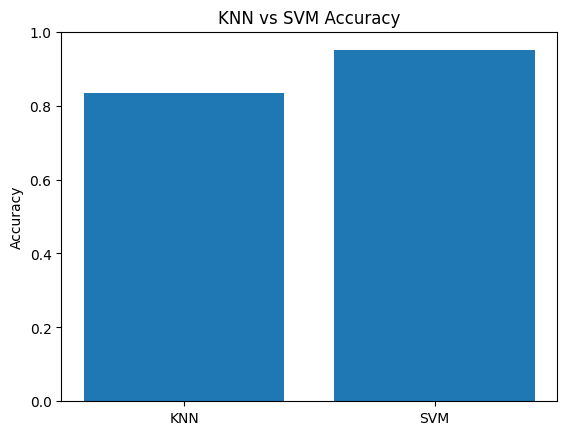

In [14]:

accuracy = [
    accuracy_score(y_test, knn_pred),
    accuracy_score(y_test, svm_pred)
]

plt.bar(["KNN", "SVM"], accuracy)
plt.title("KNN vs SVM Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()
